## Detecção de Imagens Manuscritas com Keras usando dados MNIST

Neste exercício trabalharemos com dados de imagem: especificamente o famoso conjunto de dados MNIST. Este conjunto de dados contém 70.000 imagens de dígitos manuscritos em tons de cinza (0=preto, 255 = branco). As imagens são de 28 pixels por 28 pixels para um total de 784 pixels. Isso é bem pequeno pelos padrões de imagem. Além disso, as imagens são bem centralizadas e isoladas. Isso torna este problema solucionável com redes neurais totalmente conectadas padrão sem muito pré-processamento.

Na primeira parte deste notebook, vamos orientá-lo no carregamento dos dados, construção de uma rede e seu treinamento. Então será sua vez de experimentar diferentes modelos e ver se consegue melhorar o desempenho

In [2]:
# Preliminares

from __future__ import absolute_import, division, print_function  # Compatibilidade Python 2/3

import warnings
warnings.filterwarnings("ignore")

import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

In [1]:
## Importar objetos do Keras para Deep Learning

import tensorflow.keras as keras
from tensorflow.keras.datasets import mnist
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.optimizers import RMSprop

I0000 00:00:1788891990.965700 2160666 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Vamos explorar um pouco o conjunto de dados

In [3]:
# Carregar os dados, embaralhados e divididos entre conjuntos de treino e teste (x_train e y_train)
(x_train, y_train), (x_test, y_test) = mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step


In [4]:
x_train[0].shape

(28, 28)

In [5]:
# Vamos apenas observar um exemplo específico para ver o que há dentro

x_train[333]  ## Apenas um array numpy 28 x 28 de inteiros de 0 a 255

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  87, 138,
        170, 253, 201, 244, 212, 222, 138,  86,  22,   0,   0,   0,   0,
          0,   0],
       [  

In [6]:
# Qual é o rótulo correspondente no conjunto de treinamento?
y_train[333]

np.uint8(8)

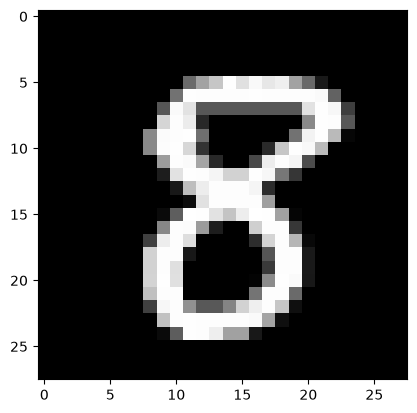

In [7]:
# Vamos ver como essa imagem realmente se parece

plt.imshow(x_train[333], cmap='Greys_r')

In [8]:
# esta é a forma do np.array x_train
# é tridimensional.
print(x_train.shape, 'amostras de treino')
print(x_test.shape, 'amostras de teste')

(60000, 28, 28) amostras de treino
(10000, 28, 28) amostras de teste


In [9]:
## Para nossos propósitos, essas imagens são apenas um vetor de 784 entradas, então vamos converter
x_train = x_train.reshape(len(x_train), 28*28)
x_test = x_test.reshape(len(x_test), 28*28)

## Keras funciona com floats, então devemos converter os números para floats
x_train = x_train.astype('float32')
x_test = x_test.astype('float32')

## Normalizar as entradas para que estejam entre 0 e 1
x_train /= 255
x_test /= 255

In [10]:
# converter vetores de classe em matrizes de classe binárias
num_classes = 10
y_train = keras.utils.to_categorical(y_train, num_classes)
y_test = keras.utils.to_categorical(y_test, num_classes)

y_train[333]  # agora o dígito k é representado por um 1 na k-ésima entrada (indexada em 0) do vetor de comprimento 10

array([0., 0., 0., 0., 0., 0., 0., 0., 1., 0.])

In [11]:
# Construiremos um modelo com duas camadas ocultas de tamanho 512
# Entradas totalmente conectadas em cada camada
# Usaremos dropout de 0.2 para ajudar na regularização
model_1 = Sequential([
    Dense(64, activation='relu', input_shape=(784,)),
    Dropout(0.2),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(10, activation='softmax')
])

In [12]:
## Note que este modelo tem MUITOS parâmetros
model_1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 64)             │        50,240 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

In [13]:
# Vamos compilar o modelo
learning_rate = .001
model_1.compile(loss='categorical_crossentropy',
              optimizer=RMSprop(learning_rate=learning_rate),
              metrics=['accuracy'])
# note que `categorical cross entropy` é a generalização natural 
# da função de perda que tínhamos no caso de classificação binária, para o caso multiclasse

In [14]:
# E agora vamos treinar.

batch_size = 128  # mini-batch com 128 exemplos
epochs = 30
history = model_1.fit(
    x_train, y_train,
    batch_size=batch_size,
    epochs=epochs,
    verbose=1,
    validation_data=(x_test, y_test))

Epoch 1/30


W0000 00:00:1788894079.546181 2160666 cpu_allocator_impl.cc:82] Allocation of 188160000 exceeds 10% of free system memory.


456/469 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.8368 - loss: 0.5443

W0000 00:00:1788894082.760462 2160666 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8388 - loss: 0.5373 - val_accuracy: 0.9341 - val_loss: 0.2134
Epoch 2/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9217 - loss: 0.2617 - val_accuracy: 0.9494 - val_loss: 0.1595
Epoch 3/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9377 - loss: 0.2098 - val_accuracy: 0.9596 - val_loss: 0.1273
Epoch 4/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9455 - loss: 0.1822 - val_accuracy: 0.9635 - val_loss: 0.1184
Epoch 5/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9497 - loss: 0.1667 - val_accuracy: 0.9674 - val_loss: 0.1098
Epoch 6/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9552 - loss: 0.1511 - val_accuracy: 0.9695 - val_loss: 0.0999
Epoch 7/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 3ms/step - accuracy: 0.9571 - loss: 0.1430 - val_accuracy: 0.9713 - val_loss: 0.0977
Epoch 8/30
469/469 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - accuracy: 0.9598 - loss: 0.1345 - val_accuracy: 0.9709 - val_

In [15]:
## Usaremos a função evaluate do Keras para avaliar o desempenho no conjunto de teste

score = model_1.evaluate(x_test, y_test, verbose=0)
print('Perda no teste:', score[0])
print('Precisão no teste:', score[1])

Perda no teste: 0.09042153507471085
Precisão no teste: 0.9775000214576721


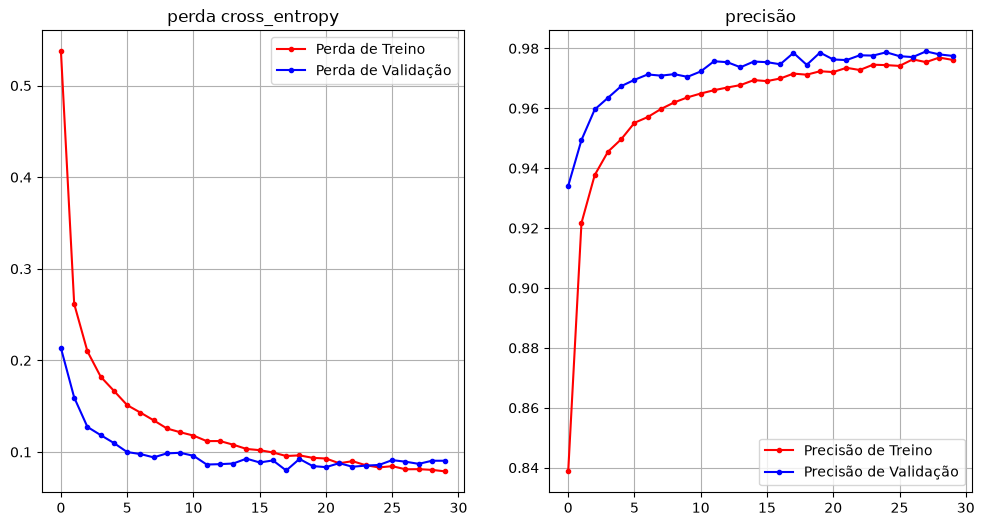

In [18]:
def plot_loss_accuracy(history):
    fig = plt.figure(figsize=(12, 6))
    ax = fig.add_subplot(1, 2, 1)
    ax.plot(history.history["loss"],'r-x', marker='.', label="Perda de Treino")
    ax.plot(history.history["val_loss"],'b-x', marker='.', label="Perda de Validação")
    ax.legend()
    ax.set_title('perda cross_entropy')
    ax.grid(True)


    ax = fig.add_subplot(1, 2, 2)
    ax.plot(history.history["accuracy"],'r', marker='.', label="Precisão de Treino")
    ax.plot(history.history["val_accuracy"],'b', marker='.', label="Precisão de Validação")
    ax.legend()
    ax.set_title('precisão')
    ax.grid(True)
    

plot_loss_accuracy(history)

Este é um desempenho razoavelmente bom, mas podemos fazer ainda melhor! A seguir, você construirá uma rede ainda maior e comparará o desempenho.

## Exercício
### Sua vez: Construa seu próprio modelo
Use a funcionalidade "Sequential" do Keras para construir `model_2` com as seguintes especificações:

1. Duas camadas ocultas.
2. Primeira camada oculta de tamanho 400 e segunda de tamanho 300
3. Dropout de 0.4 em cada camada
4. Quantos parâmetros seu modelo tem? Como ele se compara com o modelo anterior?
4. Treine este modelo por 20 épocas com RMSProp a uma taxa de aprendizado de 0.001 e tamanho de lote de 128




In [28]:
### Construa seu modelo aqui

from tensorflow.keras import layers, regularizers
from tensorflow.keras.models import Sequential
from tensorflow.keras.optimizers import RMSprop
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam

In [22]:
model2 = Sequential([
    layers.Dense(400, input_shape=(784, ), activation="relu",),
    layers.Dropout(0.4),
    layers.Dense(300, activation="relu"),
    layers.Dropout(0.4),
    layers.Dense(10, activation='softmax')
])

In [23]:
model2.compile(loss='categorical_crossentropy',
              optimizer=RMSprop(learning_rate=0.001),
              metrics=["accuracy"])

model2.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 400)            │       314,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 400)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 300)            │       120,300 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 300)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 10)             │         3,010 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 437,310 (1.67 MB)

 Trainable params: 437,310 (1.67 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
"""
O modelo tem bem mais parâmetros, 436k vs 55k, Devido ao número de neurônios bem maior nas camadas ocultas"""

''

## SOLUÇÃO

In [ ]:
history_2 = model2.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    batch_size=128,
    epochs=20,
    verbose='auto'
)

Epoch 1/20


W0000 00:00:1788896372.193326 2160666 cpu_allocator_impl.cc:82] Allocation of 188160000 exceeds 10% of free system memory.


469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - accuracy: 0.8996 - loss: 0.3327

W0000 00:00:1788896378.437046 2160666 cpu_allocator_impl.cc:82] Allocation of 31360000 exceeds 10% of free system memory.


469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 10ms/step - accuracy: 0.8996 - loss: 0.3327 - val_accuracy: 0.9610 - val_loss: 0.1292
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9542 - loss: 0.1534 - val_accuracy: 0.9718 - val_loss: 0.0940
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 10ms/step - accuracy: 0.9648 - loss: 0.1173 - val_accuracy: 0.9757 - val_loss: 0.0835
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9703 - loss: 0.1009 - val_accuracy: 0.9784 - val_loss: 0.0778
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9731 - loss: 0.0897 - val_accuracy: 0.9784 - val_loss: 0.0730
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9766 - loss: 0.0802 - val_accuracy: 0.9783 - val_loss: 0.0763
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9779 - loss: 0.0736 - val_accuracy: 0.9796 - val_loss: 0.0722
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 9ms/step - accuracy: 0.9797 - loss: 0.0670 - val_accuracy: 0.9812 - va

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9842 - loss: 0.0802
Perda no Teste: 0.08016010373830795, Acurácia no Teste: 0.9842000007629395


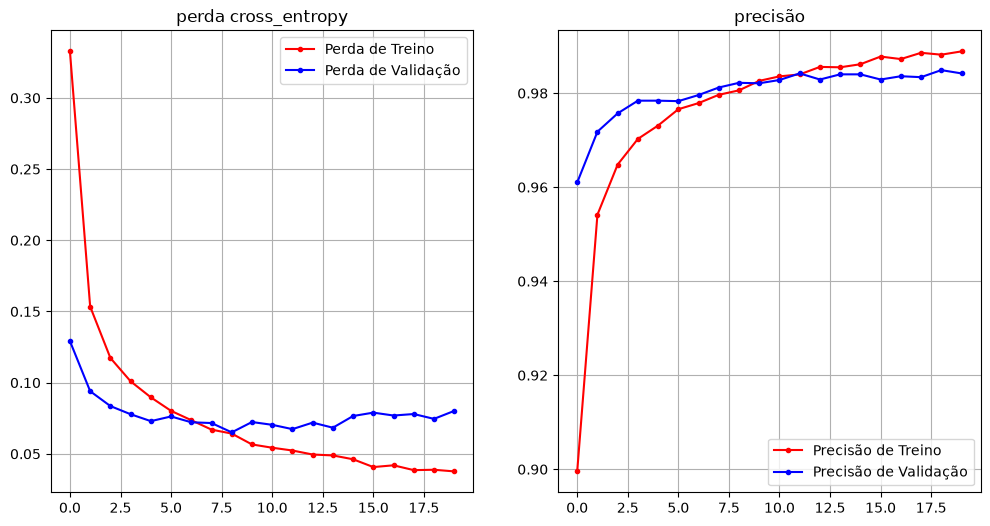

In [26]:
score2 = model2.evaluate(x_test, y_test, verbose='auto')
print(f'Perda no Teste: {score2[0]}, Acurácia no Teste: {score2[1]}')

plot_loss_accuracy(history_2)

## Pense sobre as seguintes questões

1) Como model_1 e model_2 se comparam? Qual você prefere? Se você fosse colocar um em produção, qual escolheria e por quê?

2) Compare as trajetórias da função de perda no conjunto de treinamento e no conjunto de teste para cada modelo? Como elas se comparam? O que isso sugere sobre cada modelo? Faça o mesmo para a precisão? Qual você acha mais significativo, a perda ou a precisão?

3) Sugira uma melhoria para um dos modelos (mudança de estrutura, taxa de aprendizado, número de épocas, etc.) que você acha que resultará em um modelo melhor. Teste abaixo? Isso melhorou o desempenho?

In [ ]:
"""
1 e 3: 

model1 e model2 tiveram resultados parecidos, model2 tem uma acurácia levemente maior e perda menor, mas, ainda tem indícios
de que pode ter sofrido overfitting. Para produção, eles tem resultados bem parecidos, sendo sincero, acho que ainda dá para melhorar
o model2 e aumentar seu desempenho, seu gráfico de loss de treino estava começando a subir no final, esse número grande de neurônios e ter
um resultado semelhante ao bem menor, o model2 pode ter mais potencial. Sugiro usar um otimizador Adam, E colocar EarlyStop; também seria
possível adicionar l2. Com mais penalizações, eu aumentaria as épocas e abaixaria o learning rate.
"""

In [ ]:
"""
2:

No model1, a validação de teste desce mais debagar que a do model2, mas continua decrescente e só nas épocas finais que começa a ficar
maior que a de treino, indicando um caminho mais regular e de mais aprendizado que o do model2, que, por sua parte, começa com um erro menor,
mas tendo sua trajetória analisada, é bem irregular e indica overfitting, tendo uma distância maior do erro de treino do que o model1.

Sobre as acurácias, a do model1 começa menor também, mas em nenhum momento fica menor do que a de treino, e tem um crescimento mais regular
que o do model2, que começa alto mas fica variando muito, e no final fica menor que o de treino.

O model2 tem sinais claros de overfiting, mas têm potencial, o model1 parece bem mais regular e aprende melhor, mesmo com menos neurônios;
A loss parece um meio de observação melhor que a acurácia para mim, conseguimos entender mais sobre como o modelo está aprendendo do que a 
acurácia puramente.
"""

''

In [30]:
model3 = Sequential([
    layers.Dense(400, input_shape=(784, ), activation="relu", kernel_regularizer=regularizers.l2(0.01)),
    layers.Dropout(0.4),
    layers.Dense(300, activation="relu", kernel_regularizer=regularizers.l2(0.01)),
    layers.Dropout(0.4),
    layers.Dense(10, activation='softmax', kernel_regularizer=regularizers.l2(0.01))
])

model3.compile(loss='categorical_crossentropy',
              optimizer=Adam(learning_rate=0.0001),
              metrics=["accuracy"])

early_stop = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True)

history_3 = model3.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    batch_size=128,
    epochs=20,
    verbose='auto',
    callbacks=[early_stop]
)

Epoch 1/20


W0000 00:00:1788898295.660842 2160666 cpu_allocator_impl.cc:82] Allocation of 188160000 exceeds 10% of free system memory.


469/469 ━━━━━━━━━━━━━━━━━━━━ 9s 14ms/step - accuracy: 0.7051 - loss: 6.4958 - val_accuracy: 0.8979 - val_loss: 3.6071
Epoch 2/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8650 - loss: 2.6700 - val_accuracy: 0.9127 - val_loss: 1.8243
Epoch 3/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8827 - loss: 1.5575 - val_accuracy: 0.9155 - val_loss: 1.2036
Epoch 4/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8908 - loss: 1.1394 - val_accuracy: 0.9200 - val_loss: 0.9525
Epoch 5/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8964 - loss: 0.9678 - val_accuracy: 0.9202 - val_loss: 0.8501
Epoch 6/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.8989 - loss: 0.8935 - val_accuracy: 0.9189 - val_loss: 0.8092
Epoch 7/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - accuracy: 0.9005 - loss: 0.8606 - val_accuracy: 0.9202 - val_loss: 0.7850
Epoch 8/20
469/469 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - accuracy: 0.9019 - loss: 0.8430 - val_accuracy: 0.921

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - accuracy: 0.9237 - loss: 0.7454
Perda no Teste: 0.08016010373830795, Acurácia no Teste: 0.9842000007629395


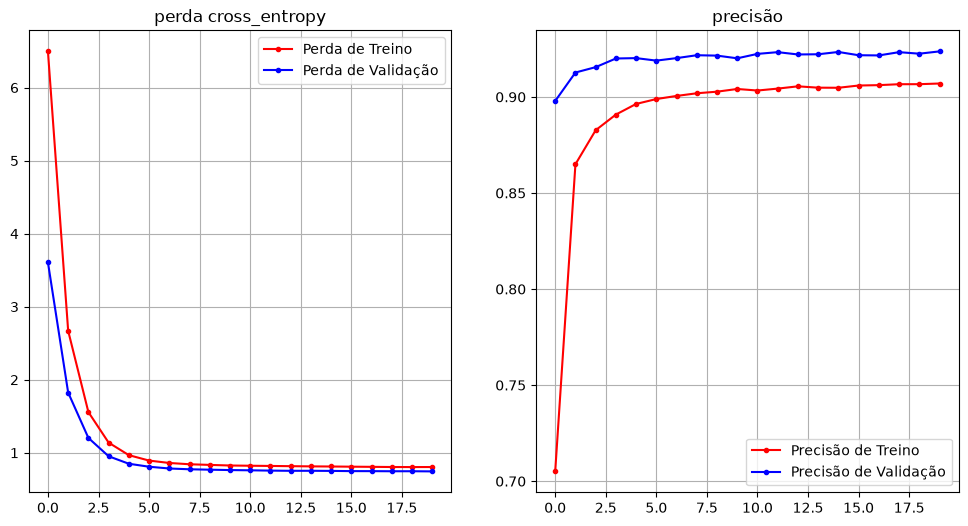

In [31]:
score3 = model3.evaluate(x_test, y_test, verbose='auto')
print(f'Perda no Teste: {score2[0]}, Acurácia no Teste: {score2[1]}')

plot_loss_accuracy(history_3)

In [ ]:
"""
Analisando o gráfico, o aprendizado é bem melhor e o EarlyStop cumpre seu papel.
O modelo está com uma acurácia boa e a perda está bem baixa, e sem suspeita de overfitting agora,
a learning_rate já está baixa e o modelo já está com um aprendizado satisfatório
"""